# Predicción de la carga de primera falla en estructuras pantográficas

Melissa Dessire Aylas Barranca · Universidad Nacional de Ingeniería · Maestría en Inteligencia Artificial  
Trabajo de Investigación II · Docente: Glen Dario Rodríguez Rafael

## Diccionario de datos

La respuesta es una fuerza en newtons (N). Las medidas geométricas están disponibles antes del ensayo. Los identificadores se usan para seguir cada probeta y quedan fuera del entrenamiento como predictores.

| Variable del análisis | Unidad | Función | Definición |
|---|---|---|---|
| `carga_primera_falla_N` | N | Respuesta | Fuerza medida cuando se registra la primera rotura de una fibra o de un pivote. |
| `numero_celdas_y` | conteo | Predictora geométrica | Número de celdas de la estructura en la dirección Y. |
| `altura_fibra` | mm | Predictora geométrica | Altura de la sección transversal de las fibras. |
| `ancho_fibra` | mm | Predictora geométrica | Ancho de la sección transversal de las fibras según la tabla curada. Hay diferencias entre fuentes geométricas. |
| `longitud_total_fibras` | mm | Predictora geométrica | Longitud total declarada del conjunto de fibras. |
| `volumen_total_fibras` | mm³ | Predictora geométrica | Volumen total declarado del conjunto de fibras. |
| `altura_pivote` | mm | Predictora geométrica | Altura nominal de los pivotes que unen las fibras. |
| `radio_pivote` | mm | Predictora geométrica | Radio nominal de los pivotes. Es constante en esta campaña. |
| `numero_total_pivotes` | conteo | Predictora geométrica | Número total de pivotes de la estructura. |
| `volumen_total_pivotes` | mm³ | Predictora geométrica | Volumen total declarado de los pivotes. |
| `volumen_total_probeta` | mm³ | Predictora geométrica | Volumen total de la probeta según el modelo CAD. |
| `id_probeta` | — | Identificación | Identificador de la pieza física ensayada. Permite unir mediciones y predicciones. |
| `registro_origen` | — | Trazabilidad | Referencia al registro del que procede la fila en la fuente. |

## 1. Datos y validación

### 1.1 Entradas y resultados disponibles

Se utiliza la geometría A curada, las particiones por grupos y los resultados iniciales ya verificados. El baseline y la selección se recuperan de esa comparación. Después se reproduce la evaluación del ganador con las mismas reservas y el pipeline existente.


In [1]:
from pathlib import Path
import sys
sys.path.insert(0, str(Path.cwd() / "notebooks"))
from datos import cargar_datos, cargar_resultados_previos
from modelado import Analisis
import presentacion as vista
import graficas
import pandas as pd
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

In [3]:
campana = cargar_datos()
semilla_modelos = 42  # Valor registrado en los modelos aleatorios de la comparación previa.
analisis = Analisis(campana, semilla_modelos=semilla_modelos)
analisis.recuperar_comparacion(cargar_resultados_previos())
geometrias = analisis.geometrias
cargas = analisis.cargas

### 1.2 Geometría admisible antes del ensayo

La representación A utiliza dimensiones y conteos de fibras, pivotes y celdas. Se excluyen el identificador, la carga terminal, las energías y los desplazamientos registrados durante el ensayo. Cada variable conserva la unidad documentada en la fuente.

In [4]:
vista.mostrar_geometria(campana.ficha_variables, campana.decisiones_fe)

| Variable | Unidad | Medida geométrica |
| :--- | :--- | :--- |
| numero_celdas_y | conteo | Número de celdas en la dirección Y; indicador de la arquitectura. |
| altura_fibra | mm | Altura de la sección de las fibras. |
| ancho_fibra | mm | Ancho de sección; algunas fuentes geométricas discrepan. |
| longitud_total_fibras | mm | Longitud declarada del conjunto de fibras, vinculada al nivel Y. |
| volumen_total_fibras | mm³ | Volumen declarado de fibras; relacionado con el de pivotes. |
| altura_pivote | mm | Altura nominal de los elementos de unión. |
| radio_pivote | mm | Radio nominal del pivote; constante en la campaña. |
| numero_total_pivotes | conteo | Cantidad de conexiones; depende de la arquitectura observada. |
| volumen_total_pivotes | mm³ | Volumen declarado del conjunto de uniones. |
| volumen_total_probeta | mm³ | Volumen declarado del espécimen según CAD; no se sustituye por una suma. |

**Variantes geométricas B–D y motivo para conservar A**

| experimento | referencia | intervencion | delta_MAE_N | decision |
| :--- | :--- | :--- | ---: | :--- |
| B | A | Añadir dos segundos momentos de área de la sección de fibra | -0,412 | Mantener en evaluación |
| C | B | Añadir ln(volumen_pivotes / volumen_fibras) | 0,079 | Descartar |
| D | C | Retirar longitud total de fibras, número de pivotes y volumen de fibras del bloque original | 4,121 | Descartar |

### 1.3 Grupos reservados para evaluar la predicción

| Protocolo | Grupo que se aparta antes de ajustar el modelo | Qué se evalúa |
|---|---|---|
| Configuración nominal | Probetas con la misma combinación de celdas en Y, altura de fibra y altura de pivote. | Predecir otra combinación geométrica con niveles Y ya observados. |
| Nivel celular Y | Todas las probetas con el mismo número de celdas en Y. | Predecir un nivel ausente del entrenamiento. Retirar un nivel intermedio prueba interpolación en Y y retirar un extremo prueba extrapolación en Y. |

Las probetas con la misma clave nominal permanecen juntas. La campaña no documenta si constituyen réplicas de fabricación.

## 2. Baseline y selección del mejor modelo

### 2.1 Referencias preliminares

La referencia principal es la media de carga del entrenamiento para el mismo nivel Y. Al reservar completamente ese nivel, se utiliza la media global del entrenamiento. La mediana y Ridge histórico se conservan como referencias adicionales. Todas las métricas corresponden a los mismos grupos reservados.

In [5]:
vista.mostrar_referencias(analisis.metricas_referencia)

| Referencia | MAE [N] | RMSE [N] | R² | MAE nivel Y [N] |
| :--- | ---: | ---: | ---: | ---: |
| Media por nivel Y | 10,126 | 12,308 | 0,956 | 80,593 |
| Ridge histórico | 13,247 | 16,346 | 0,923 | 57,637 |
| Mediana de entrenamiento | 49,748 | 64,699 | -0,213 | 97,511 |

Con el nivel Y presente en entrenamiento, la media por nivel tiene un error de 10,13 N. Al reservar el nivel completo, la media de entrenamiento da 80,59 N.

### 2.2 Modelo seleccionado

La selección toma el menor MAE al reservar configuraciones en la comparación preliminar ya realizada. Se consideran los resultados iniciales de regresión lineal, SVR, XGBoost, CatBoost, K vecinos y árbol de decisión. El criterio se aplica en el código a la tabla completa. Los apartados posteriores desarrollan el modelo elegido.

In [6]:
comparacion_inicial = analisis.metricas_preliminares
comparables = comparacion_inicial.loc[
    comparacion_inicial.protocolo.eq("configuracion")
    & comparacion_inicial.procedimiento.isin(analisis.modelos_iniciales)
]
modelo_elegido = comparables.set_index("procedimiento").MAE_N.idxmin()
vista.nota(f"**Modelo seleccionado · {vista.nombre(modelo_elegido)}**")

**Modelo seleccionado · Lineal múltiple**

In [7]:
vista.mostrar_resultados_ganador(analisis)

| Protocolo | MAE [N] | RMSE [N] | R² | Sesgo [N] | Mejora MAE frente al baseline [N] | Mejora MAE [%] |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: |
| Configuración reservada | 9,664 | 12,308 | 0,956 | -0,289 | 0,462 | 4,564 |
| Nivel Y ausente del ajuste | 40,915 | 46,337 | 0,378 | -15,052 | 39,678 | 49,233 |

<div style="background-color: #e9f5ec; color: #233c2b; padding: 0.8em 1em; border: 0; border-radius: 0.35em;">

1. La regresión lineal múltiple obtiene el menor MAE de la comparación inicial, 9,664 N al reservar configuraciones.
2. Frente al baseline de 10,126 N, la reducción es 0,462 N (4,56 %).
3. Al reservar un nivel Y completo, el MAE del modelo es 40,915 N, frente a 80,593 N de la referencia. La selección se realizó con el protocolo de configuraciones reservadas.

</div>

### 2.3 Error del ganador frente al baseline

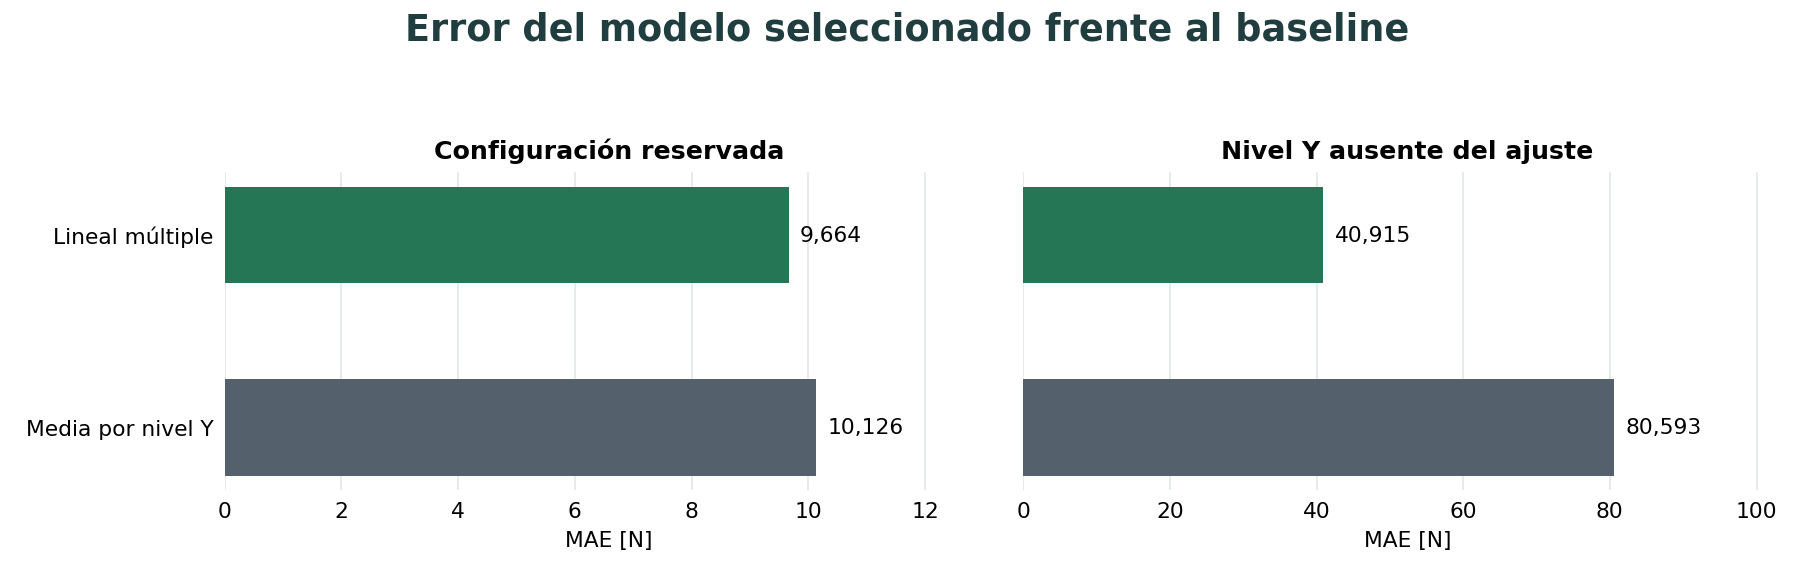

In [8]:
graficas.mostrar(graficas.errores_ganador, analisis.metricas, analisis.mejor)

Cada barra muestra el MAE en newtons. Los paneles corresponden a los dos protocolos de reserva. Una barra más corta indica menor error. Cada panel usa su propia escala horizontal.

<div style="background-color: #e9f5ec; color: #233c2b; padding: 0.8em 1em; border: 0; border-radius: 0.35em;">

El modelo reduce el MAE en 0,462 N con niveles Y conocidos y en 39,678 N al retirar un nivel. El MAE de la regresión lineal aumenta de 9,664 a 40,915 N entre esos protocolos, por lo que su capacidad de transferencia exige una evaluación específica.

</div>

## 3. Ajuste de la regresión lineal seleccionada

### 3.1 Ecuación y estimación de los coeficientes

El modelo calcula $\hat F=\beta_0+\sum_j \beta_j x_j$. Los coeficientes y el intercepto se estiman minimizando la suma de errores cuadrados de entrenamiento. La base independiente conserva las columnas geométricas que aumentan el rango numérico.

### 3.2 Preprocesamiento reutilizado

Se utiliza el pipeline existente. La mediana para imputar, la eliminación de constantes, el escalado y la base independiente se estimaron en cada entrenamiento de la evaluación original. El reajuste final usa ese mismo procedimiento sobre la campaña para obtener una ecuación de uso posterior.

### 3.3 Configuración del ajuste

La especificación seleccionada utiliza mínimos cuadrados con intercepto y tolerancia relativa de la base de $10^{-10}$. El ajuste estima sus coeficientes directamente. La optimización de hiperparámetros queda sin aplicar a esta especificación, por lo que sus resultados se presentan como regresión lineal inicial.

La solución lineal es determinista. La semilla 42 se aplicó a XGBoost, CatBoost y árbol durante la comparación previa. La evaluación y el reajuste de la regresión lineal se obtienen del solucionador de mínimos cuadrados.

In [9]:
vista.mostrar_configuracion_ganador(analisis)

| Elemento | Valor |
| :--- | :--- |
| Estimador | Lineal múltiple |
| Estimación | Mínimos cuadrados ordinarios |
| Intercepto | True |
| Tolerancia relativa de la base | 1e-10 |
| Optimización de hiperparámetros | No aplicada a esta especificación de mínimos cuadrados |
| Aleatoriedad del ajuste lineal | Solución determinista |

In [10]:
parametros_modelo = {"fit_intercept": True}
preprocesamiento = analisis.preparar_preprocesamiento(modelo_elegido, analisis.configuracion)
modelo_ganador = Pipeline([
    *preprocesamiento,
    ("regresor", LinearRegression(**parametros_modelo)),
])

## 4. Evaluación del modelo seleccionado

### 4.1 Entrenamiento y predicción por grupos

Se recorren las reservas existentes. Cada clon del pipeline se ajusta con el entrenamiento de ese pliegue y predice las geometrías reservadas. La imputación, el escalado y la base independiente se estiman dentro de cada entrenamiento.


In [11]:
reservas = analisis.particiones_por_grupo
predicciones = []
for protocolo, particiones in reservas.items():
    for pliegue, (entrenamiento, prueba) in enumerate(particiones, start=1):
        modelo_pliegue = clone(modelo_ganador)
        modelo_pliegue.fit(geometrias.iloc[entrenamiento], cargas.iloc[entrenamiento])
        carga_predicha = modelo_pliegue.predict(geometrias.iloc[prueba])
        predicciones.append(pd.DataFrame({
            "procedimiento": modelo_elegido,
            "protocolo": protocolo,
            "pliegue": pliegue,
            "id_probeta": geometrias.index[prueba],
            "observado_N": cargas.iloc[prueba].to_numpy(),
            "predicho_N": carga_predicha,
        }))
predicciones = pd.concat(predicciones, ignore_index=True)

In [12]:
predicciones["residuo_N"] = predicciones.observado_N - predicciones.predicho_N
predicciones["error_absoluto_N"] = predicciones.residuo_N.abs()
analisis.verificar_predicciones_seleccionadas(predicciones)

### 4.2 Cálculo de las métricas

El MAE promedia $|\hat F-F|$ y el RMSE es la raíz del promedio de $(\hat F-F)^2$. Ambos se expresan en newtons. El sesgo es el promedio de predicción menos medición. R² compara la suma de errores cuadrados con la variación de las cargas observadas dentro del protocolo.

In [13]:
metricas_ganador = []
for protocolo, grupo in predicciones.groupby("protocolo", sort=False):
    observada, predicha = grupo.observado_N, grupo.predicho_N
    metricas_ganador.append({
        "Protocolo": vista.PROTO[protocolo],
        "MAE [N]": mean_absolute_error(observada, predicha),
        "RMSE [N]": root_mean_squared_error(observada, predicha),
        "R²": r2_score(observada, predicha),
        "Sesgo [N]": (predicha - observada).mean(),
    })
vista.tabla(pd.DataFrame(metricas_ganador))

| Protocolo | MAE [N] | RMSE [N] | R² | Sesgo [N] |
| :--- | ---: | ---: | ---: | ---: |
| Configuración reservada | 9,664 | 12,308 | 0,956 | -0,289 |
| Nivel Y ausente del ajuste | 40,915 | 46,337 | 0,378 | -15,052 |

El ejemplo siguiente recupera una probeta reservada y muestra su error individual. La última columna reúne los errores de todas las configuraciones reservadas.

In [14]:
vista.mostrar_calculo_mae(*analisis.ejemplo_mae())

| Procedimiento | Carga medida [N] | Predicción [N] | Error de esta probeta [N] | MAE de configuraciones reservadas [N] |
| :--- | ---: | ---: | ---: | ---: |
| Media por nivel Y | 59,680 | 70,313 | 10,633 | 10,126 |
| Lineal múltiple | 59,680 | 71,923 | 12,243 | 9,664 |

### 4.3 Carga observada y predicha

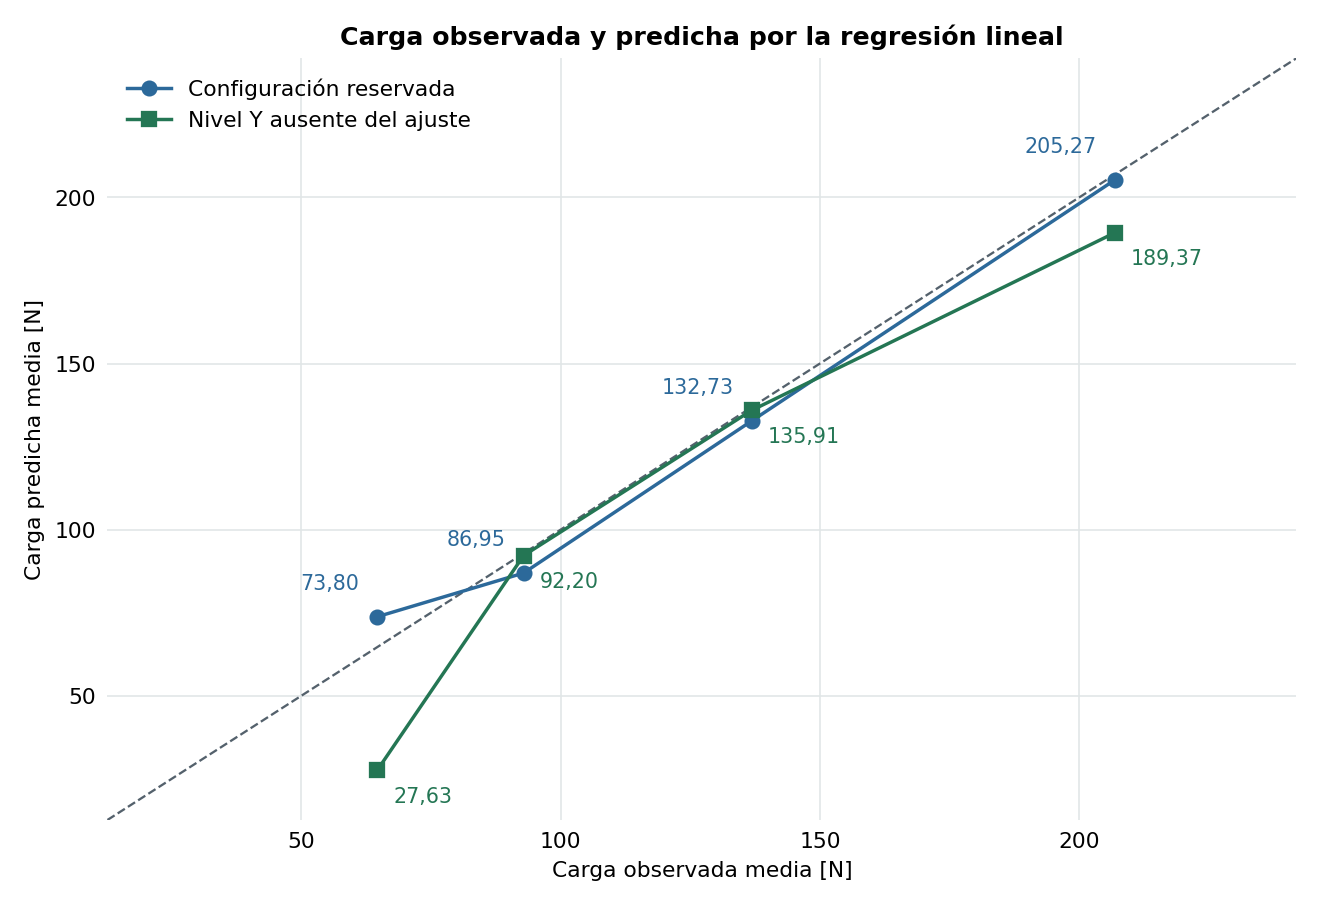

In [15]:
graficas.mostrar(graficas.cargas_ganador, analisis.predicciones_ganador)

Cada marca representa las medias de carga observada y predicha en un cuartil de carga observada. Las etiquetas muestran la predicción media en newtons. Una curva por debajo de la diagonal indica subestimación en ese tramo.

<div style="background-color: #e9f5ec; color: #233c2b; padding: 0.8em 1em; border: 0; border-radius: 0.35em;">

En el tramo de mayor carga, la media observada es 206,89 N. El modelo predice 205,27 N al reservar configuraciones y 189,37 N al retirar un nivel Y. La subestimación del tramo alto aumenta al retirar el nivel.

</div>

### 4.4 Diagnóstico de residuos

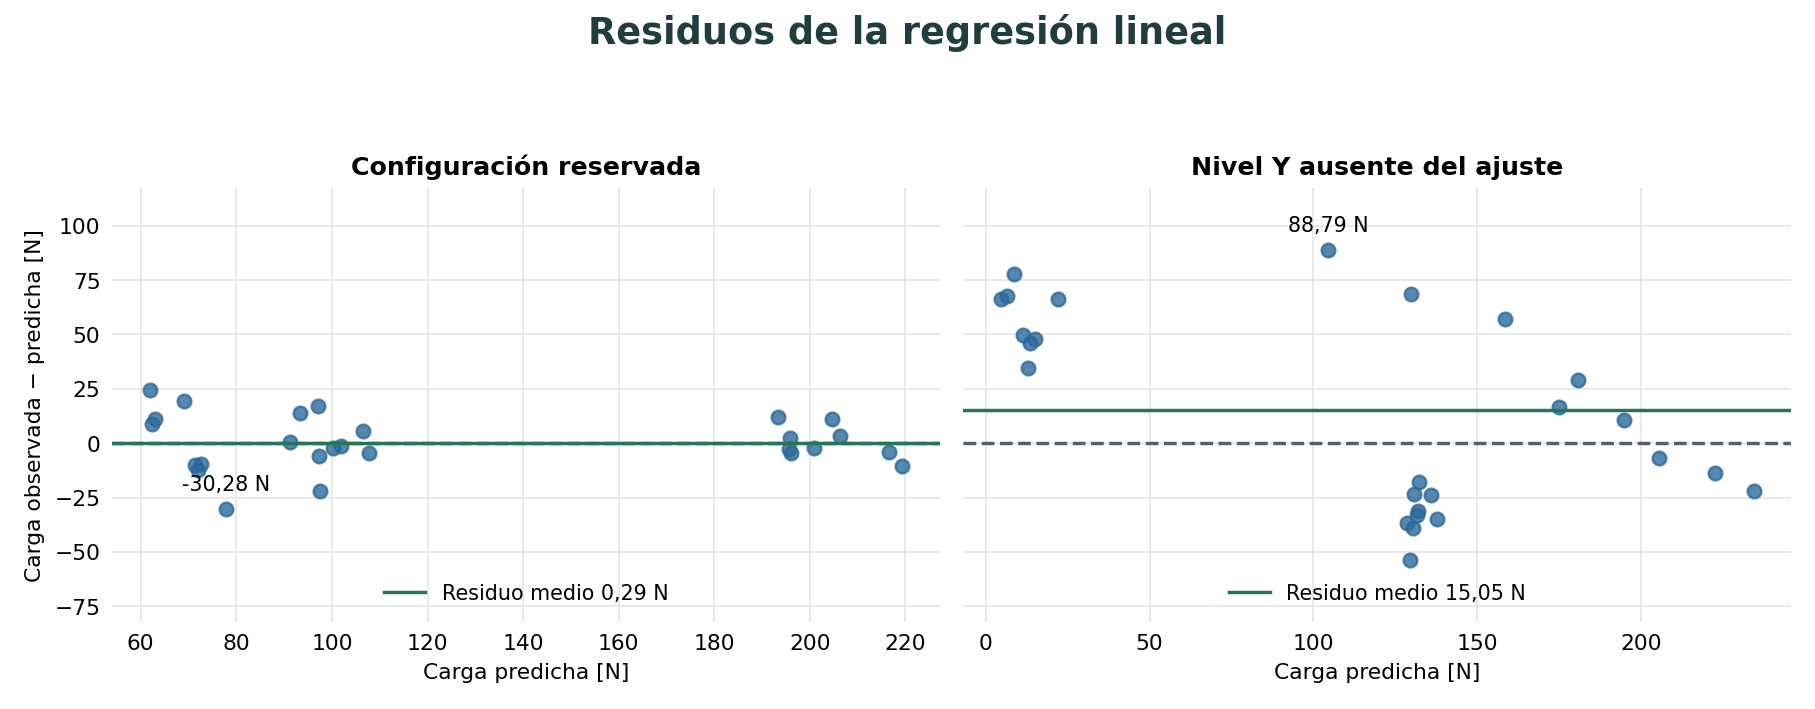

In [16]:
graficas.mostrar(graficas.residuos_ganador, analisis.predicciones_ganador)

Cada punto muestra la carga observada menos la predicha. Un residuo positivo indica subestimación. La línea discontinua marca el error cero, la verde muestra el residuo medio y la etiqueta identifica el residuo de mayor magnitud.

<div style="background-color: #e9f5ec; color: #233c2b; padding: 0.8em 1em; border: 0; border-radius: 0.35em;">

El residuo medio es 0,289 N por configuración y 15,052 N al retirar un nivel Y. Estos promedios describen el desplazamiento general de las predicciones. Los errores de signos opuestos pueden compensarse, por lo que se interpretan junto con el MAE.

</div>

### 4.5 Distribución del error absoluto

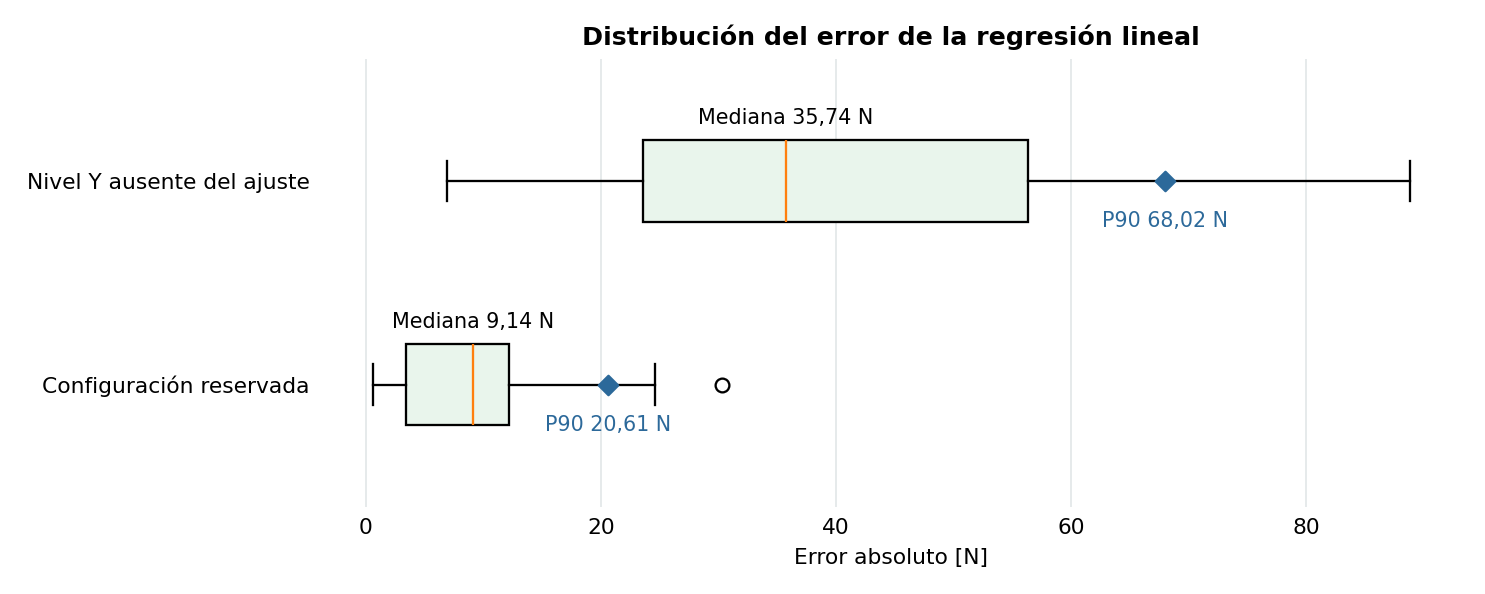

In [17]:
graficas.mostrar(graficas.distribucion_ganador, analisis.predicciones_ganador)

La caja abarca los cuartiles 25 y 75 y su línea central marca la mediana. Los bigotes siguen la regla de 1,5 veces el rango intercuartílico. El rombo azul señala el percentil 90. Las etiquetas muestran ambos valores en newtons.

<div style="background-color: #e9f5ec; color: #233c2b; padding: 0.8em 1em; border: 0; border-radius: 0.35em;">

Al reservar configuraciones, la mediana del error es 9,136 N y el percentil 90 alcanza 20,607 N. Al retirar un nivel Y, esos valores son 35,745 N y 68,023 N. El aumento afecta tanto al error central como a la cola superior.

</div>

In [18]:
vista.mostrar_resumen_errores(analisis.predicciones_ganador)

| Protocolo | Mediana [N] | Percentil 90 [N] | Máximo [N] |
| :--- | ---: | ---: | ---: |
| Configuración reservada | 9,136 | 20,607 | 30,281 |
| Nivel Y ausente del ajuste | 35,745 | 68,023 | 88,789 |

## 5. Ecuación y resultados finales

### 5.1 Arquitectura y ecuación del modelo seleccionado

Se reajusta la regresión lineal con la campaña para presentar su ecuación en unidades originales. Las métricas anteriores proceden de los grupos reservados. La ecuación final requiere comprobación en ensayos futuros.


In [19]:
modelo_ganador = modelo_ganador.fit(geometrias, cargas)
ecuacion_ganadora = analisis.ecuacion_en_unidades_originales(modelo_ganador)

In [20]:
vista.presentar_arquitectura(
    modelo_elegido, modelo_ganador,
    analisis.unidades, ecuacion_ganadora
)

**Lineal múltiple**

Validar geometría A → Imputar con la mediana → Quitar constantes → Estandarizar → Conservar una base independiente → LinearRegression → **Carga de primera falla [N]**

**Ecuación en unidades originales**

**F̂ [N] = -2028,48292047 + Σⱼ βⱼ xⱼ**

Cada xⱼ es la geometría en la unidad de la tabla. Si falta, se usa la mediana indicada. Los coeficientes βⱼ ya incorporan el escalado del ajuste por mínimos cuadrados.

| Variable xⱼ | Unidad de xⱼ | Mediana de imputación | βⱼ [N por unidad] |
| :--- | :--- | :--- | :--- |
| numero_celdas_y | conteo | 5,000000 | -455,94867855 |
| altura_fibra | mm | 1,200000 | -0,48826335 |
| ancho_fibra | mm | 1,690000 | 10,13978564 |
| longitud_total_fibras | mm | 3178,560000 | 1,07955303 |
| volumen_total_fibras | mm³ | 6362,930000 | 0,25798285 |
| altura_pivote | mm | 1,200000 | 7,28901396 |
| volumen_total_probeta | mm³ | 6464,715000 | -0,10710200 |

Constantes en el reajuste: `radio_pivote`. Redundantes en la base elegida: `numero_total_pivotes`, `volumen_total_pivotes`. La base conserva las columnas que aumentan el rango en el orden de entrada (tolerancia relativa 1e-10). Las pendientes describen esta base. La dependencia entre geometrías limita su interpretación física individual.

### 5.2 Resultados y alcance

<div style="background-color: #e9f5ec; color: #233c2b; padding: 0.8em 1em; border: 0; border-radius: 0.35em;">

1. La regresión lineal múltiple es el modelo inicial con menor MAE por configuración, 9,664 N. La mejora frente a la media por nivel es 0,462 N.
2. El criterio operativo registrado exige al menos 1 N de mejora en MAE, junto con estabilidad por grupos y control del RMSE. La ventaja observada queda por debajo de ese umbral. La media por nivel se conserva como referencia operativa para niveles conocidos.
3. El modelo seleccionado alcanza 40,915 N de MAE al retirar un nivel Y. Este incremento limita la generalización a arquitecturas con niveles ausentes del ajuste.
4. La selección del ganador utiliza resultados ya observados de esta campaña. Su confirmación requiere una evaluación independiente. El reajuste final prepara la ecuación para esa etapa.

</div>